In [3]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)
from sklearn.pipeline import Pipeline

In [4]:
df = pd.read_csv("fakenews.csv")


In [5]:
# Handle missing values
df["headline"] = df["headline"].fillna("")
df["body_text"] = df["body_text"].fillna("")

# Combine headline and body text
df["text"] = df["headline"] + " " + df["body_text"]

# Remove rows with missing labels
df = df.dropna(subset=["label"])

In [6]:
# Prepare features and target
X = df["text"]
y = df["label"]

In [7]:
# Check class distribution
print("Class Distribution:")
print(y.value_counts())

Class Distribution:
label
Fake    1110
Real    1102
Name: count, dtype: int64


In [8]:
# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


In [9]:


# Define tokenization strategies
models = {
    "Word-Level": Pipeline([
        (
            "vectorizer",
            CountVectorizer(
                analyzer="word",
                ngram_range=(1, 2),
                max_features=10000
            )
        ),
        (
            "classifier",
            LogisticRegression(max_iter=1000)
        )
    ]),

    "Character-Level": Pipeline([
        (
            "vectorizer",
            TfidfVectorizer(
                analyzer="char",
                ngram_range=(2, 5),
                max_features=10000
            )
        ),
        (
            "classifier",
            LogisticRegression(max_iter=1000)
        )
    ])
}


In [12]:

# Store results
results = []

# Train and evaluate both models
for name, model in models.items():

    print(f"\nTraining {name} Model...")

    model.fit(X_train, y_train)

    # Predict test data
    y_pred = model.predict(X_test)

    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, average="weighted", zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, average="weighted", zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred, average="weighted", zero_division=0
    )
    

    # Save results
    results.append({
        "Tokenization": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

    print(f"\n{name} Classification Report:")
    print(classification_report(
        y_test, y_pred, zero_division=0
    ))


Training Word-Level Model...

Word-Level Classification Report:
              precision    recall  f1-score   support

        Fake       0.52      0.45      0.48       222
        Real       0.52      0.59      0.55       221

    accuracy                           0.52       443
   macro avg       0.52      0.52      0.52       443
weighted avg       0.52      0.52      0.52       443


Training Character-Level Model...

Character-Level Classification Report:
              precision    recall  f1-score   support

        Fake       0.47      0.43      0.45       222
        Real       0.47      0.51      0.49       221

    accuracy                           0.47       443
   macro avg       0.47      0.47      0.47       443
weighted avg       0.47      0.47      0.47       443



In [13]:


# Compare results
results_df = pd.DataFrame(results)

print("\nTokenization Performance Comparison:")
print(results_df.round(4))



Tokenization Performance Comparison:
      Tokenization  Accuracy  Precision  Recall  F1-Score
0       Word-Level    0.5192     0.5197  0.5192    0.5169
1  Character-Level    0.4718     0.4717  0.4718    0.4710


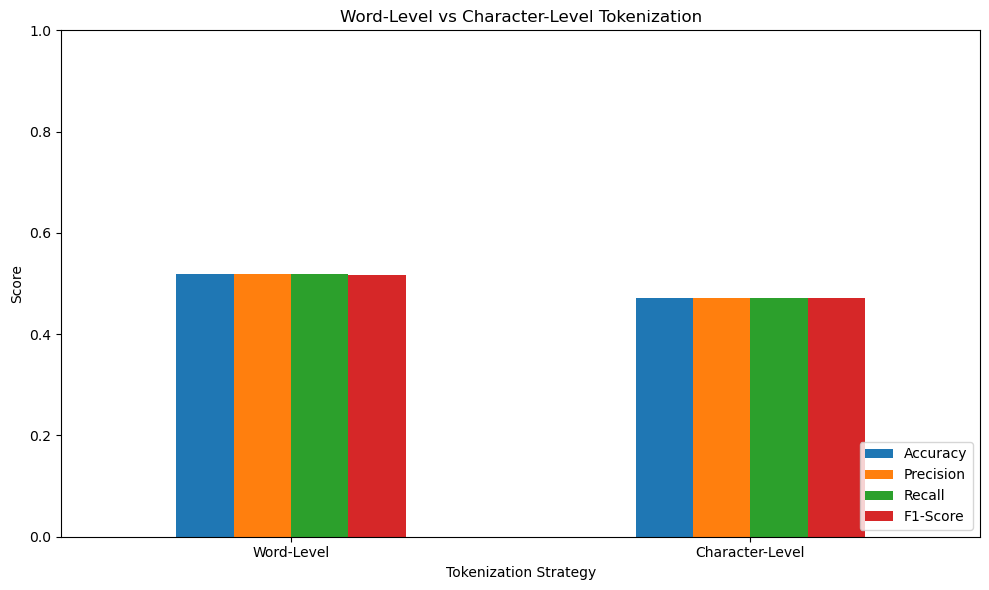

In [14]:

# Plot performance comparison
results_df.set_index("Tokenization").plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Word-Level vs Character-Level Tokenization")
plt.ylabel("Score")
plt.xlabel("Tokenization Strategy")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [15]:

# Identify the model with the highest F1-score
best_model = results_df.loc[
    results_df["F1-Score"].idxmax()
]

print("\nBest Performing Tokenization Strategy:")
print(best_model["Tokenization"])
print("F1-Score:", round(best_model["F1-Score"], 4))




Best Performing Tokenization Strategy:
Word-Level
F1-Score: 0.5169
